# COMET vs. CellOracle on Paul et al. 2015 data (density-robust metrics)

Same flow as `compare_to_celloracle_newmethod.ipynb`, but the agreement metrics are replaced.
COMET puts nonzero weight on ~44% of the motif mask, CellOracle on ~8% (~5x sparser). The old
symmetric top-K Jaccard / union-Spearman are capped by CellOracle's sparsity, so their per-TF
scores track CellOracle's hub (= support) size rather than real agreement. Here CellOracle's edges
are the **reference** and we score how well COMET *ranks* them — metrics that don't inherit that
confound.

Kernel: `decipher-env`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.metrics import average_precision_score
import os

COMET_BASE = "/home/elicanter/paul2015_outputs_newmethod_d6"
CO_REF = "/home/elicanter/datasets/paul2015data/celloracle_reference"
EPS = 1e-6

mix_weights = np.load(f"{COMET_BASE}/mix_weights.npy")   # (n_cells, D)
A_dict      = np.load(f"{COMET_BASE}/A_dict.npy")        # (D, G, T) residual modules
A_base      = np.load(f"{COMET_BASE}/A_base.npy")        # (G, T) shared base
A_learned   = np.load(f"{COMET_BASE}/A_learned.npy")     # (G, T) population GRN
A_genes     = np.load(f"{COMET_BASE}/A_genes.npy", allow_pickle=True).astype(str)
A_tfs       = np.load(f"{COMET_BASE}/A_tfs.npy", allow_pickle=True).astype(str)

n_cells, D = mix_weights.shape
G, T = len(A_genes), len(A_tfs)
print(f"COMET: {n_cells} cells, D={D} modules, G={G} genes, T={T} TFs")

cell_meta = pd.read_csv(f"{CO_REF}/cell_metadata.csv", index_col=0)
co_genes_all = np.load(f"{CO_REF}/base_grn_genes.npy", allow_pickle=True).astype(str)
co_tfs_all   = np.load(f"{CO_REF}/base_grn_tfs.npy", allow_pickle=True).astype(str)
assert len(cell_meta) == n_cells, "cell count mismatch -- positional alignment breaks"

cluster_names = sorted(f.replace(".csv", "") for f in os.listdir(f"{CO_REF}/edges_by_cluster"))
edges_by_cluster = {cl: pd.read_csv(f"{CO_REF}/edges_by_cluster/{cl}.csv") for cl in cluster_names}
print(f"CellOracle clusters: {cluster_names}")

COMET: 2671 cells, D=6 modules, G=1850 genes, T=90 TFs
CellOracle clusters: ['10GMP', '12Baso', '13Baso', '14Mo', '15Mo', '16Neu', '17Neu', '1Ery', '2Ery', '3Ery', '4Ery', '5Ery', '6Ery', '7MEP', '8Mk', '9GMP']


## Align gene/TF universes

Restrict both sides to their shared, identically-ordered gene/TF universe and build the per-cluster
CellOracle GRNs plus a cell-count-weighted pooled global GRN.

In [2]:
common_genes = np.intersect1d(A_genes, co_genes_all)
common_tfs   = np.intersect1d(A_tfs, co_tfs_all)
print(f"Shared genes: {len(common_genes)}/{len(A_genes)} COMET, {len(co_genes_all)} CO")
print(f"Shared TFs:   {len(common_tfs)}/{len(A_tfs)} COMET, {len(co_tfs_all)} CO")

g_idx = pd.Index(A_genes).get_indexer(common_genes)
t_idx = pd.Index(A_tfs).get_indexer(common_tfs)
A_dict    = A_dict[:, g_idx][:, :, t_idx]
A_base    = A_base[g_idx][:, t_idx]
A_learned = A_learned[g_idx][:, t_idx]
A_genes, A_tfs = common_genes, common_tfs
G, T = len(A_genes), len(A_tfs)

gene_pos = {g: i for i, g in enumerate(A_genes)}
tf_pos   = {t: i for i, t in enumerate(A_tfs)}

def edges_to_matrix(df, value_col="coef_mean"):
    """Long CellOracle edge table -> dense signed (G, T) matrix on the shared universe."""
    mat = np.zeros((G, T), dtype=np.float32)
    df = df[df["target"].isin(gene_pos) & df["source"].isin(tf_pos)]
    mat[df["target"].map(gene_pos).to_numpy(), df["source"].map(tf_pos).to_numpy()] = df[value_col].to_numpy()
    return mat

co_cluster_mats = {cl: edges_to_matrix(df) for cl, df in edges_by_cluster.items()}
cluster_sizes = cell_meta["paul15_clusters"].value_counts()
w = np.array([cluster_sizes.get(cl, 0) for cl in co_cluster_mats]); w = w / w.sum()
co_global = np.tensordot(w, np.stack(list(co_cluster_mats.values())), axes=1)
print(f"Built {len(co_cluster_mats)} cluster GRNs + pooled global GRN, shape {co_global.shape}")

Shared genes: 1848/1850 COMET, 1850 CO
Shared TFs:   89/90 COMET, 90 CO
Built 16 cluster GRNs + pooled global GRN, shape (1848, 89)


## Metrics — reference-anchored, density-robust

CellOracle's edges are the reference; COMET's `|weight|` ranks them. All three divide out each TF's
edge prevalence, so a TF is not penalised just for CellOracle being sparse for it.

- **AUPRC-lift** — per-TF AUPRC / its random baseline (edge prevalence). `1 = chance`.
- **EPR** (early-precision ratio) — precision among COMET's top-`P` edges (`P` = #CellOracle edges),
  over the same baseline. `1 = chance`.
- **sign precision** — of the CellOracle edges COMET recovers in its top-`P`, fraction with matching sign.

In [3]:
def per_tf_reference_metrics(pred, ref, eps=EPS, min_pos=10):
    """Per TF: AUPRC-lift, EPR, raw AUPRC, and #reference edges.
    positives = CellOracle edges; candidates = genes nonzero in either method; score = |pred|.
    TFs with < min_pos reference edges (or no negatives) are left NaN."""
    T_ = pred.shape[1]
    lift = np.full(T_, np.nan); epr = np.full(T_, np.nan)
    auprc = np.full(T_, np.nan); n_pos = np.zeros(T_, dtype=int)
    for t in range(T_):
        p, r = np.abs(pred[:, t]), np.abs(ref[:, t])
        cand = np.flatnonzero((p > eps) | (r > eps))
        y = (r[cand] > eps).astype(int)
        P, N = int(y.sum()), len(cand); n_pos[t] = P
        if P < min_pos or P == N:
            continue
        s = p[cand]; baseline = P / N
        auprc[t] = average_precision_score(y, s)
        lift[t]  = auprc[t] / baseline
        epr[t]   = (y[np.argsort(s)[::-1][:P]].sum() / P) / baseline
    return lift, epr, auprc, n_pos


def per_tf_sign_precision(pred, ref, eps=EPS, min_pos=10):
    """Fraction of recovered reference edges (in pred's top-P) whose sign matches."""
    T_ = pred.shape[1]; out = np.full(T_, np.nan)
    for t in range(T_):
        ps, rs = pred[:, t], ref[:, t]
        cand = np.flatnonzero((np.abs(ps) > eps) | (np.abs(rs) > eps))
        ps_c, rs_c = ps[cand], rs[cand]
        P = int((np.abs(rs_c) > eps).sum())
        if P < min_pos:
            continue
        topP = np.argsort(np.abs(ps_c))[::-1][:P]
        rec = np.abs(rs_c[topP]) > eps
        if rec.sum():
            out[t] = (np.sign(ps_c[topP][rec]) == np.sign(rs_c[topP][rec])).mean()
    return out


def per_tf_topk_jaccard(g1, g2, top_frac=0.20, eps=EPS):
    """Symmetric top-K overlap -- only valid when both GRNs have similar density,
    so used below ONLY for CellOracle-vs-CellOracle cluster comparisons."""
    T_ = g1.shape[1]; out = np.full(T_, np.nan)
    for t in range(T_):
        ax, ay = np.abs(g1[:, t]), np.abs(g2[:, t])
        nx, ny = np.flatnonzero(ax > eps), np.flatnonzero(ay > eps)
        if len(nx) == 0 or len(ny) == 0:
            continue
        k = max(1, round(top_frac * len(np.union1d(nx, ny))))
        tx = set(nx[np.argsort(ax[nx])[::-1][:min(k, len(nx))]])
        ty = set(ny[np.argsort(ay[ny])[::-1][:min(k, len(ny))]])
        out[t] = len(tx & ty) / len(tx | ty)
    return out

## Population-level comparison

COMET's global GRN (`A_learned`) vs. the pooled CellOracle GRN.

In [4]:
lift, epr, auprc, n_pos = per_tf_reference_metrics(A_learned, co_global)
sign_prec = per_tf_sign_precision(A_learned, co_global)
hub_comet = np.abs(A_learned).sum(0); hub_co = np.abs(co_global).sum(0)
hub_rho = spearmanr(hub_comet, hub_co).correlation
n_scored = int(np.isfinite(epr).sum())

print("=== COMET global GRN vs CellOracle pooled GRN (density-robust) ===")
print(f"scored on {n_scored}/{T} TFs (>= 10 CellOracle edges)")
print(f"AUPRC-lift  mean: {np.nanmean(lift):.2f}x     (1 = chance)")
print(f"EPR         mean: {np.nanmean(epr):.2f}x     (1 = chance)")
print(f"sign prec.  mean: {np.nanmean(sign_prec):.2f}      (direction agreement on recovered edges)")
print(f"hub-score Spearman: {hub_rho:.2f}       (do both methods agree which TFs are hubs)")

=== COMET global GRN vs CellOracle pooled GRN (density-robust) ===
scored on 86/89 TFs (>= 10 CellOracle edges)
AUPRC-lift  mean: 2.67x     (1 = chance)
EPR         mean: 2.67x     (1 = chance)
sign prec.  mean: 0.59      (direction agreement on recovered edges)
hub-score Spearman: 0.79       (do both methods agree which TFs are hubs)


## Is the score still confounded by support size?

Because AUPRC-lift and EPR divide out each TF's edge prevalence (which equals CellOracle's per-TF
support, i.e. its hub score), their per-TF values should no longer track the CellOracle hub axis —
the artifact that made the old scores fade for sparse TFs. Raw AUPRC still does (kept here to show
the contrast).

In [5]:
def hub_corr(a):
    return spearmanr(hub_co, a, nan_policy="omit").correlation

print("per-TF score vs CellOracle hub score  (near 0 = confound removed):")
print(f"  raw AUPRC  : {hub_corr(auprc):+.2f}   <- still prevalence-driven")
print(f"  AUPRC-lift : {hub_corr(lift):+.2f}")
print(f"  EPR        : {hub_corr(epr):+.2f}")

per-TF score vs CellOracle hub score  (near 0 = confound removed):
  raw AUPRC  : +0.57   <- still prevalence-driven
  AUPRC-lift : -0.01
  EPR        : -0.08


## Sparsity structure: COMET vs. CellOracle

COMET is ~5x denser than CellOracle. Three views of what that density is:

1. **Edge-weight distribution** — are COMET's extra (COMET-only) edges just small weights?
2. **Precision–recall** — as we take COMET's strongest edges, how fast do we recover CellOracle's?
3. **Density-matched overlap** — keep only COMET's top-`P` edges per TF (`P` = CellOracle's edge count)
   and compare, so the two are scored at equal density.

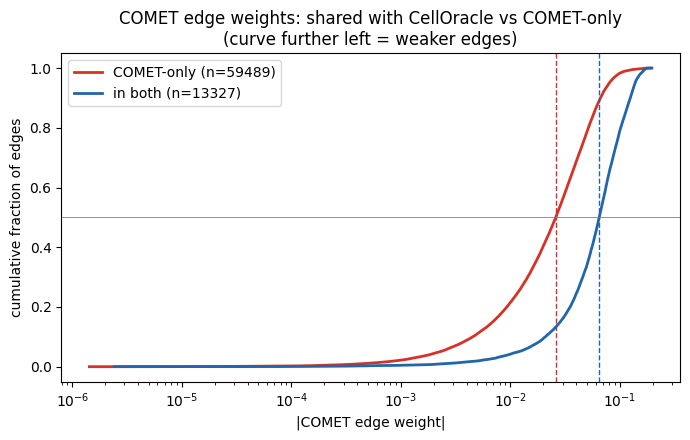

COMET-only edges are weaker: median 0.026 vs 0.065 shared; 89% fall below the shared-edge median.


In [6]:
# Fig 1 - are COMET's extra (COMET-only) edges just small weights? Cumulative distribution of
# |COMET weight|, split by whether the edge is also in CellOracle. A curve further LEFT = weaker
# edges; the value at any x is the fraction of that group below that weight. (ECDF, no bin artifacts.)
cx = np.abs(A_learned) > EPS                  # COMET edges
cy = np.abs(co_global) > EPS                  # CellOracle edges
w_shared = np.sort(np.abs(A_learned)[cx & cy])
w_only   = np.sort(np.abs(A_learned)[cx & ~cy])

fig, ax = plt.subplots(figsize=(7, 4.5))
for w, color, lab in [(w_only,   "#d73027", f"COMET-only (n={len(w_only)})"),
                      (w_shared, "#2166ac", f"in both (n={len(w_shared)})")]:
    ax.plot(w, np.arange(1, len(w) + 1) / len(w), color=color, lw=2, label=lab)
    ax.axvline(np.median(w), color=color, ls="--", lw=1)   # median = where the curve crosses 0.5
ax.axhline(0.5, color="grey", lw=0.6)
ax.set_xscale("log")
ax.set_xlabel("|COMET edge weight|"); ax.set_ylabel("cumulative fraction of edges")
ax.set_title("COMET edge weights: shared with CellOracle vs COMET-only\n(curve further left = weaker edges)")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()
print(f"COMET-only edges are weaker: median {np.median(w_only):.3f} vs {np.median(w_shared):.3f} shared; "
      f"{(w_only < np.median(w_shared)).mean():.0%} fall below the shared-edge median.")

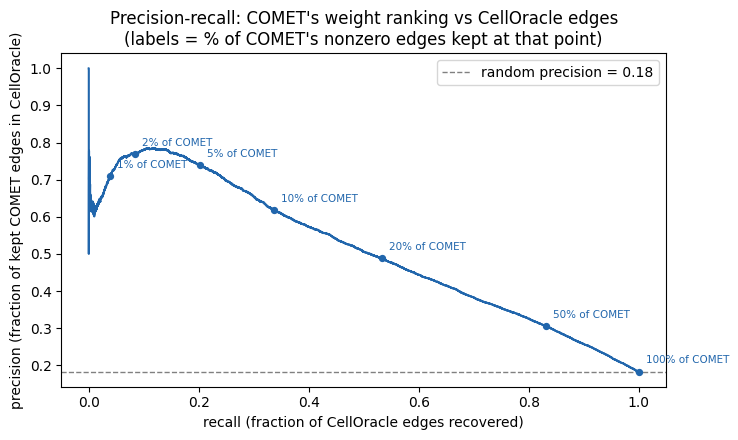

In [7]:
# Fig 2 - rank COMET's edges by |weight|; as we keep the strongest top-k, what fraction are
# CellOracle edges (precision) and what fraction of CellOracle we've recovered (recall).
# random precision is computed on the same candidate set as everything else here: COMET's nonzero
# (cx) edges only. Edges COMET's prior already zeroed out are never candidates, so they're excluded
# from both the curve and the baseline -- base_prec is "precision if you kept ALL of COMET's nonzero
# edges unranked", not "precision over all G x T pairs".
w_flat = np.abs(A_learned)[cx]
is_co  = cy[cx][np.argsort(w_flat)[::-1]]
kept   = np.arange(1, is_co.size + 1)
precision = np.cumsum(is_co) / kept
recall    = np.cumsum(is_co) / (cx & cy).sum()
base_prec = (cx & cy).sum() / cx.sum()
pct_of_comet = kept / is_co.size   # fraction of COMET's nonzero edges included at this point

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(recall, precision, color="#2166ac")
ax.axhline(base_prec, color="grey", ls="--", lw=1, label=f"random precision = {base_prec:.2f}")

# label the curve with what % of COMET's nonzero edges are kept at that point
label_pcts = [0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0]
for lp in label_pcts:
    idx = min(np.searchsorted(pct_of_comet, lp), len(pct_of_comet) - 1)
    ax.scatter(recall[idx], precision[idx], color="#2166ac", s=18, zorder=3)
    ax.annotate(f"{lp:.0%} of COMET", (recall[idx], precision[idx]), fontsize=7.5,
                xytext=(5, 6), textcoords="offset points",
                arrowprops=None, color="#2166ac")

ax.set_xlabel("recall (fraction of CellOracle edges recovered)")
ax.set_ylabel("precision (fraction of kept COMET edges in CellOracle)")
ax.set_title("Precision-recall: COMET's weight ranking vs CellOracle edges\n(labels = % of COMET's nonzero edges kept at that point)")
ax.legend(); plt.tight_layout(); plt.show()

## Magnitude-based filtering: global vs. per-TF vs. per-gene

scale of per-group median |weight| (how uniform is magnitude across the group):
  per-TF   : range 0.0136-0.0443  (3.3x)   corr(edge-count, median|w|) rho=+0.20
  per-gene : range 0.0014-0.1707  (119.0x)   corr(edge-count, median|w|) rho=-0.00


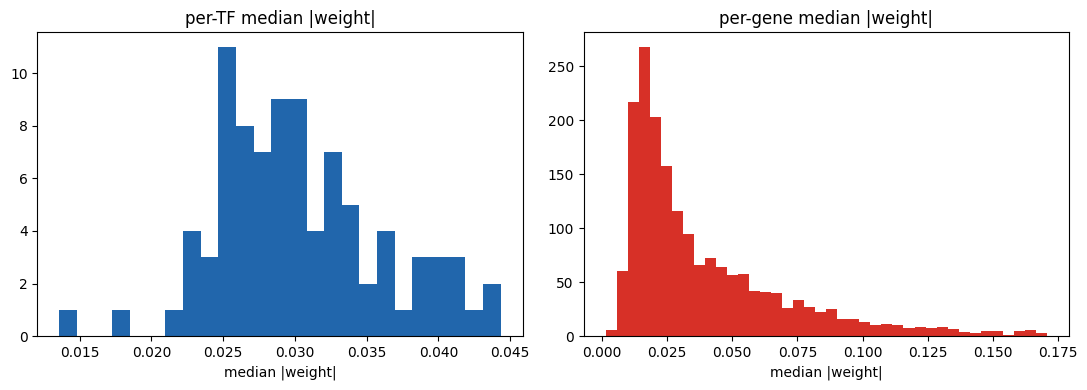

In [8]:
# Does |weight| sit on the same scale across TFs (columns) and across genes (rows)?
# If a group's median weight is systematically low/high independent of its own edge count,
# a *global* cutoff would over/under-prune that group regardless of confidence.
med_w_tf   = np.array([np.median(np.abs(A_learned[:, t][cx[:, t]])) if cx[:, t].any() else np.nan
                       for t in range(T)])
med_w_gene = np.array([np.median(np.abs(A_learned[g, :][cx[g, :]])) if cx[g, :].any() else np.nan
                       for g in range(G)])
deg_tf, deg_gene = cx.sum(0), cx.sum(1)

rho_tf   = spearmanr(deg_tf, med_w_tf, nan_policy="omit").correlation
rho_gene = spearmanr(deg_gene, med_w_gene, nan_policy="omit").correlation

print("scale of per-group median |weight| (how uniform is magnitude across the group):")
print(f"  per-TF   : range {np.nanmin(med_w_tf):.4f}-{np.nanmax(med_w_tf):.4f}  "
      f"({np.nanmax(med_w_tf)/np.nanmin(med_w_tf):.1f}x)   corr(edge-count, median|w|) rho={rho_tf:+.2f}")
print(f"  per-gene : range {np.nanmin(med_w_gene):.4f}-{np.nanmax(med_w_gene):.4f}  "
      f"({np.nanmax(med_w_gene)/np.nanmin(med_w_gene):.1f}x)   corr(edge-count, median|w|) rho={rho_gene:+.2f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.hist(med_w_tf, bins=25, color="#2166ac"); ax1.set_title("per-TF median |weight|"); ax1.set_xlabel("median |weight|")
ax2.hist(med_w_gene, bins=40, color="#d73027"); ax2.set_title("per-gene median |weight|"); ax2.set_xlabel("median |weight|")
plt.tight_layout(); plt.show()

In [9]:
# Compare three filtering schemes at matched retention (~same total #edges kept), against
# CellOracle precision -- does grouping the cutoff by TF or by gene do better than pooling globally?
def filter_precision(keep_mask, label):
    n_kept = keep_mask.sum()
    prec = (keep_mask & cy).sum() / n_kept if n_kept else np.nan
    print(f"  {label:34s} kept={n_kept:6d} ({n_kept/cx.sum():.1%} of COMET)   precision={prec:.3f}  "
          f"({prec/base_prec:.2f}x random)")
    return prec

target_frac = 0.05   # match the ~5% retention point from the PR curve above
abs_w = np.abs(A_learned)

print(f"Filtering schemes at ~{target_frac:.0%} retention (random precision = {base_prec:.3f}):")

# 1) global: single |weight| cutoff over the whole pooled set
thresh_global = np.quantile(abs_w[cx], 1 - target_frac)
filter_precision(cx & (abs_w >= thresh_global), "global cutoff")

# 2) per-TF: keep each TF's own top target_frac of its nonzero edges
keep_tf = np.zeros_like(cx)
for t in range(T):
    idx = np.flatnonzero(cx[:, t])
    if idx.size == 0:
        continue
    k = max(1, round(target_frac * idx.size))
    top = idx[np.argsort(abs_w[idx, t])[::-1][:k]]
    keep_tf[top, t] = True
filter_precision(keep_tf, "per-TF top-frac")

# 3) per-gene: keep each gene's own top target_frac of its nonzero (incoming) edges
keep_gene = np.zeros_like(cx)
for g in range(G):
    idx = np.flatnonzero(cx[g, :])
    if idx.size == 0:
        continue
    k = max(1, round(target_frac * idx.size))
    top = idx[np.argsort(abs_w[g, idx])[::-1][:k]]
    keep_gene[g, top] = True
filter_precision(keep_gene, "per-gene top-frac")

Filtering schemes at ~5% retention (random precision = 0.183):
  global cutoff                      kept=  3641 (5.0% of COMET)   precision=0.739  (4.04x random)
  per-TF top-frac                    kept=  3641 (5.0% of COMET)   precision=0.645  (3.52x random)
  per-gene top-frac                  kept=  3682 (5.1% of COMET)   precision=0.200  (1.10x random)


0.200434546442151

Per-gene top-frac collapses toward random; per-TF is close to global. Use the global ranking.

## Cell-specific GRNs vs. their matching CellOracle cluster GRN

Each cell's GRN is `A_base + sum_d mix_weights[cell, d] * A_dict[d]`. Score it against every cluster
GRN by **top-K Jaccard** (overlap of the strongest edges), z-normalize each cluster's score column,
and take the best match vs. the true `paul15_clusters` label.

Note on the metric: here the goal is to *discriminate* clusters, not to correct for density — every
comparison is the same cell vs. a cluster, and the z-normalization already removes per-cluster scale.
The prevalence-normalized EPR / AUPRC used above actually *removes* the discriminative signal (it
divides out exactly the per-edge strength that identifies a cell type), so it collapses toward chance
here; plain Jaccard works much better for matching.

In [10]:
true_labels = cell_meta["paul15_clusters"].to_numpy()   # positional, same order as COMET arrays
N_SAMPLE, N_SHUFFLE, SEED = 400, 200, 0
TOP_FRAC = 0.20
rng = np.random.default_rng(SEED)
eligible = np.flatnonzero(np.isin(true_labels, cluster_names))
sample_idx = rng.choice(eligible, size=min(N_SAMPLE, len(eligible)), replace=False)

def tf_orders(grn_abs):
    """Per TF: nonzero gene indices sorted by |weight| desc, plus a (T, G) membership mask."""
    orders, mask = [], np.zeros((T, G), dtype=bool)
    for t in range(T):
        nz = np.flatnonzero(grn_abs[:, t] > EPS)
        orders.append(nz[np.argsort(grn_abs[nz, t])[::-1]]); mask[t, nz] = True
    return orders, mask

cl_orders, cl_mask = {}, {}
for cl, m in co_cluster_mats.items():
    cl_orders[cl], cl_mask[cl] = tf_orders(np.abs(m))

def mean_jaccard_to_cluster(cell_orders, cl, top_frac=TOP_FRAC):
    """Mean over TFs of the top-K Jaccard between the cell's and the cluster's strongest edges."""
    j = []
    for t in range(T):
        ox, oy = cell_orders[t], cl_orders[cl][t]
        if ox.size == 0 or oy.size == 0:
            continue
        overlap = cl_mask[cl][t][ox].sum()
        k = max(1, round(top_frac * (ox.size + oy.size - overlap)))   # top_frac of the union
        kx, ky = min(k, ox.size), min(k, oy.size)
        inter = np.intersect1d(ox[:kx], oy[:ky], assume_unique=True).size
        j.append(inter / (kx + ky - inter))
    return np.mean(j) if j else np.nan

scores, assigned = [], []
for i in sample_idx:
    cell_abs = np.abs(A_base + np.einsum("d,dgt->gt", mix_weights[i], A_dict))
    cell_orders, _ = tf_orders(cell_abs)
    scores.append([mean_jaccard_to_cluster(cell_orders, cl) for cl in cluster_names])
    assigned.append(true_labels[i])
scores, assigned = np.array(scores), np.array(assigned)

# z-normalize each cluster column, then argmax
Z = (scores - np.nanmean(scores, 0)) / np.nanstd(scores, 0)
Zf = np.where(np.isnan(Z), -np.inf, Z)
predicted = np.array(cluster_names)[Zf.argmax(1)]
acc = (predicted == assigned).mean()
shuffle_acc = np.array([(predicted == rng.permutation(assigned)).mean() for _ in range(N_SHUFFLE)])
own = np.array([cluster_names.index(a) for a in assigned])
ranks = (Z > Z[np.arange(len(Z)), own][:, None]).sum(1) + 1

print(f"Matching {len(sample_idx)} cells by top-{int(TOP_FRAC*100)}% Jaccard to {len(cluster_names)} cluster GRNs")
print(f"acc={acc:.3f}  shuffle={shuffle_acc.mean():.3f}+/-{shuffle_acc.std():.3f}  "
      f"mean_rank={ranks.mean():.2f}/{len(cluster_names)}  top3={(ranks<=3).mean():.3f}  "
      f"(chance acc = {1/len(cluster_names):.3f})")

Matching 400 cells by top-20% Jaccard to 16 cluster GRNs
acc=0.237  shuffle=0.062+/-0.012  mean_rank=2.81/16  top3=0.708  (chance acc = 0.062)


Confusion matrix (row-normalized) and the rank of each cell's true cluster among all clusters.

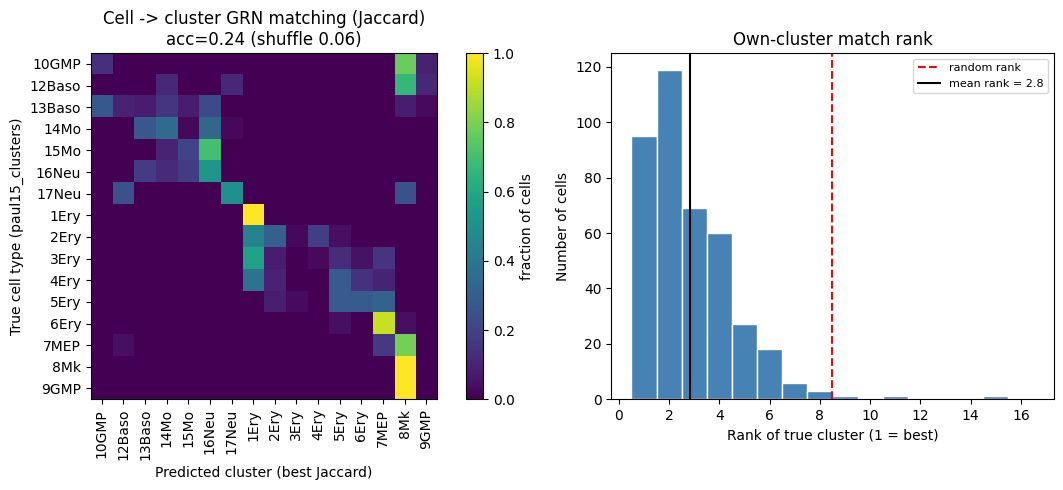

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1.3, 1]})

conf = pd.crosstab(pd.Series(assigned, name="true"), pd.Series(predicted, name="predicted"))
conf = conf.reindex(index=cluster_names, columns=cluster_names, fill_value=0)
conf_norm = conf.div(conf.sum(1).replace(0, np.nan), axis=0)
im = ax1.imshow(conf_norm.values, vmin=0, vmax=1, cmap="viridis")
ax1.set_xticks(range(len(cluster_names))); ax1.set_xticklabels(cluster_names, rotation=90)
ax1.set_yticks(range(len(cluster_names))); ax1.set_yticklabels(cluster_names)
ax1.set_xlabel("Predicted cluster (best Jaccard)"); ax1.set_ylabel("True cell type (paul15_clusters)")
ax1.set_title(f"Cell -> cluster GRN matching (Jaccard)\nacc={acc:.2f} (shuffle {shuffle_acc.mean():.2f})")
fig.colorbar(im, ax=ax1, label="fraction of cells", fraction=0.046)

ax2.hist(ranks, bins=np.arange(1, len(cluster_names) + 2) - 0.5, color="steelblue", edgecolor="white")
ax2.axvline((len(cluster_names) + 1) / 2, color="red", ls="--", label="random rank")
ax2.axvline(ranks.mean(), color="black", label=f"mean rank = {ranks.mean():.1f}")
ax2.set_xlabel("Rank of true cluster (1 = best)"); ax2.set_ylabel("Number of cells")
ax2.set_title("Own-cluster match rank"); ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Is poor matching a model problem or a reference problem?

Some CellOracle clusters have near-identical GRNs, so no method can separate them. The heatmap is
CellOracle-vs-CellOracle similarity (both sides equally sparse, so the symmetric top-K Jaccard is
valid here); the table pairs each cluster's recall with its most-similar other cluster.

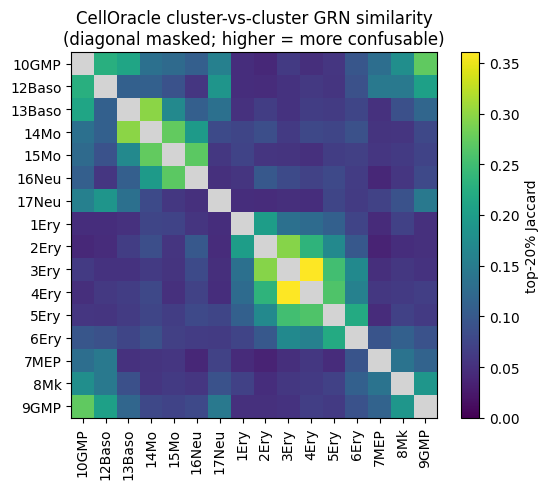

cluster  n_total  n_sampled  recall@1  recall@top3 most_similar_other  similarity
  10GMP      153         22      0.14         0.82               9GMP        0.27
 12Baso       69          9      0.00         0.67              10GMP        0.23
 13Baso      300         40      0.07         0.40               14Mo        0.30
   14Mo      373         48      0.35         0.85             13Baso        0.30
   15Mo      186         20      0.20         0.90               14Mo        0.27
  16Neu      164         34      0.53         0.68               15Mo        0.27
  17Neu       22          4      0.50         0.50             12Baso        0.19
   1Ery       43          8      1.00         1.00               2Ery        0.20
   2Ery      329         49      0.31         0.94               3Ery        0.29
   3Ery      246         40      0.00         0.10               4Ery        0.36
   4Ery      124         21      0.00         0.62               3Ery        0.36
   5Ery      180

In [12]:
K = len(cluster_names)
co_sim = np.eye(K)
for i in range(K):
    for j in range(i + 1, K):
        v = np.nanmean(per_tf_topk_jaccard(co_cluster_mats[cluster_names[i]], co_cluster_mats[cluster_names[j]]))
        co_sim[i, j] = co_sim[j, i] = v
co_sim_plot = co_sim.copy(); np.fill_diagonal(co_sim_plot, np.nan)

fig, ax = plt.subplots(figsize=(6, 5))
cmap = plt.cm.viridis.copy(); cmap.set_bad("lightgrey")
im = ax.imshow(co_sim_plot, vmin=0, vmax=np.nanmax(co_sim_plot), cmap=cmap)
ax.set_xticks(range(K)); ax.set_xticklabels(cluster_names, rotation=90)
ax.set_yticks(range(K)); ax.set_yticklabels(cluster_names)
ax.set_title("CellOracle cluster-vs-cluster GRN similarity\n(diagonal masked; higher = more confusable)")
fig.colorbar(im, ax=ax, label="top-20% Jaccard", fraction=0.046)
plt.tight_layout(); plt.show()

rows = []
for i, cl in enumerate(cluster_names):
    row = co_sim[i].copy(); row[i] = -1; nn = row.argmax()
    sel = assigned == cl
    rows.append((cl, cluster_sizes.get(cl, 0), int(sel.sum()),
                 (predicted[sel] == cl).mean() if sel.sum() else np.nan,
                 (ranks[sel] <= 3).mean() if sel.sum() else np.nan,
                 cluster_names[nn], row[nn]))
tbl = pd.DataFrame(rows, columns=["cluster", "n_total", "n_sampled", "recall@1", "recall@top3",
                                  "most_similar_other", "similarity"])
pd.set_option("display.float_format", lambda v: f"{v:.2f}")
print(tbl.to_string(index=False))

## Hub-TF agreement (density-robust)

Per-TF hub score, COMET vs. CellOracle, colored by **Jaccard-lift** (left) and **EPR** (right).
Jaccard-lift is the density-matched Jaccard (top-`P` COMET edges per TF vs CellOracle's `P`) divided
by its random-chance value — even the density-matched Jaccard still rises with CellOracle's support,
so normalizing by chance (like AUPRC-lift) removes that. Both panels are ~confound-free (correlation
with the CellOracle hub axis ≈ 0), so color reflects real agreement, not sparsity. `1 = chance`.

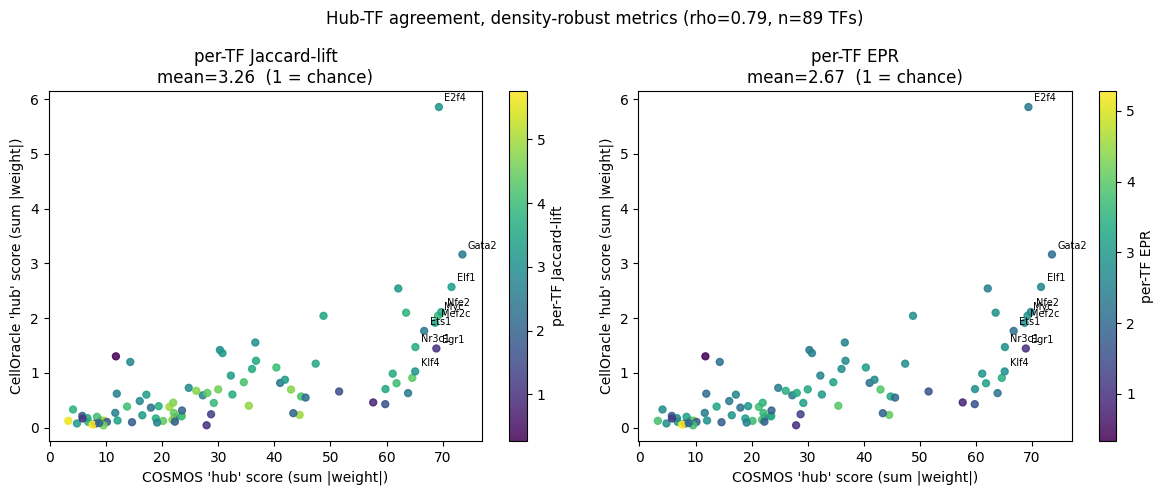

In [13]:
# Fair Jaccard: density-matched overlap (top-P COMET edges per TF vs CellOracle's P) divided by its
# random-chance value -- like AUPRC-lift but for Jaccard. Plain (even density-matched) Jaccard still
# rises with CellOracle's support; dividing by chance removes that. 1 = chance.
def per_tf_jaccard_lift(pred, ref, eps=EPS, min_pos=10):
    T_ = pred.shape[1]; out = np.full(T_, np.nan)
    for t in range(T_):
        p, r = np.abs(pred[:, t]), np.abs(ref[:, t])
        r_nz = np.flatnonzero(r > eps); P = len(r_nz)
        cand = np.flatnonzero((p > eps) | (r > eps)); N = len(cand)
        if P < min_pos or P >= N:
            continue
        p_top = np.argsort(p)[::-1][:P]                       # COMET's P strongest edges
        inter = len(set(p_top.tolist()) & set(r_nz.tolist()))
        obs = inter / (2 * P - inter)
        exp = (P * P / N) / (2 * P - P * P / N)               # chance Jaccard of two size-P sets
        out[t] = obs / exp
    return out

tf_jacc_lift = per_tf_jaccard_lift(A_learned, co_global)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, shading, label in [(axes[0], tf_jacc_lift, "per-TF Jaccard-lift"),
                           (axes[1], epr,          "per-TF EPR")]:
    cmap = plt.cm.viridis.copy(); cmap.set_bad("lightgrey")
    sc = ax.scatter(hub_comet, hub_co, c=shading, cmap=cmap,
                    vmin=np.nanmin(shading), vmax=np.nanmax(shading), s=25, alpha=0.85)
    for ti in np.argsort(hub_comet + hub_co)[-10:]:
        ax.annotate(A_tfs[ti], (hub_comet[ti], hub_co[ti]), fontsize=7,
                    xytext=(4, 4), textcoords="offset points")
    ax.set_xlabel("COSMOS 'hub' score (sum |weight|)")
    ax.set_ylabel("CellOracle 'hub' score (sum |weight|)")
    ax.set_title(f"{label}\nmean={np.nanmean(shading):.2f}  (1 = chance)")
    fig.colorbar(sc, ax=ax, label=label)
fig.suptitle(f"Hub-TF agreement, density-robust metrics (rho={hub_rho:.2f}, n={T} TFs)")
plt.tight_layout(); plt.show()

## Per-cell GRN module usage in decipher space

`mix_weights[:, d]` is how strongly each cell leans on module `d`; one decipher-space panel per module.

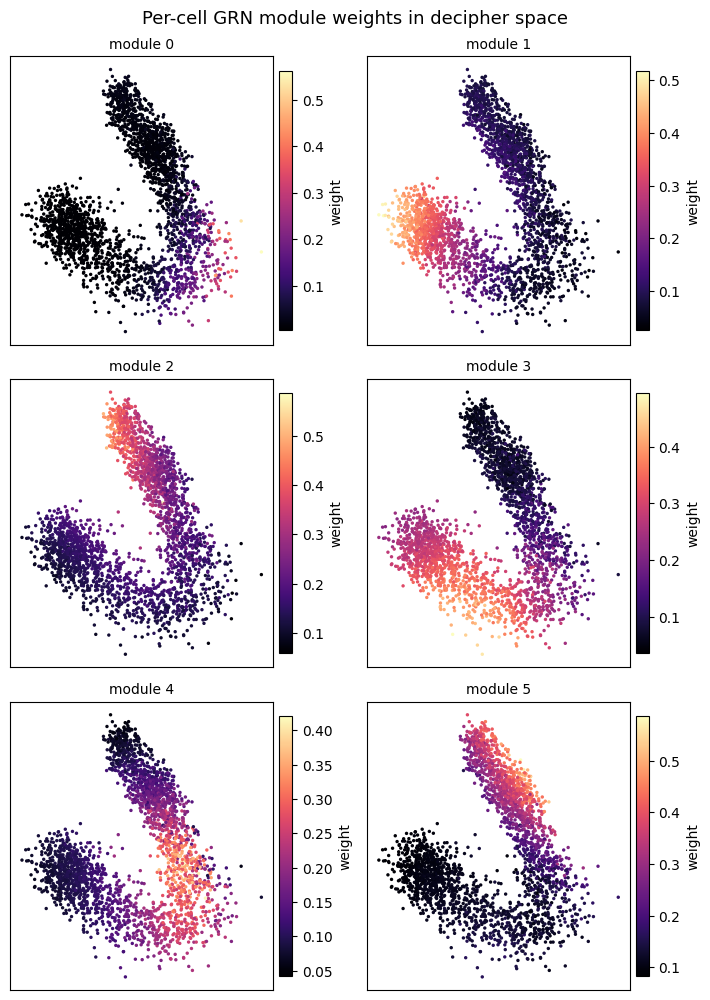

In [14]:
from config import DATA

V_dec2 = np.load(DATA["decipher_outputs"])["v"].astype(np.float32)   # (n_cells, 2)
assert V_dec2.shape[0] == mix_weights.shape[0], "decipher/mix_weights cell-count mismatch"

ncols = 2; nrows = int(np.ceil(D / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 3.4 * nrows), squeeze=False)
for d in range(D):
    ax = axes[d // ncols][d % ncols]
    sc = ax.scatter(V_dec2[:, 0], V_dec2[:, 1], c=mix_weights[:, d], cmap="magma", s=6, linewidths=0)
    ax.set_title(f"module {d}", fontsize=10); ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.02, label="weight")
for k in range(D, nrows * ncols):
    axes[k // ncols][k % ncols].axis("off")
fig.suptitle("Per-cell GRN module weights in decipher space", fontsize=13)
plt.tight_layout(); plt.show()

## COMET vs. CellOracle Jaccard-lift, P set by COMET's density (reversed)

Same idea as the Hub-TF panel above, but `P` per TF is now COMET's own edge count for that TF
(~44% dense) instead of CellOracle's (~8% dense). Because COMET is so much denser, `P` is usually
close to the full candidate set `N`, so the `P >= N` guard NaNs out most TFs -- and on the TFs
where it doesn't, "top-P of CellOracle" degenerates to just "all of CellOracle's edges" (CellOracle
rarely *has* P edges to choose from). So this isn't really a top-K comparison anymore, it's closer
to a chance-normalized full-set Jaccard between COMET's and CellOracle's edges. Included alongside
the CellOracle-P version for comparison.

COMET-density-P Jaccard-lift scored on 4/89 TFs (vs 86/89 for the CellOracle-density-P version above)


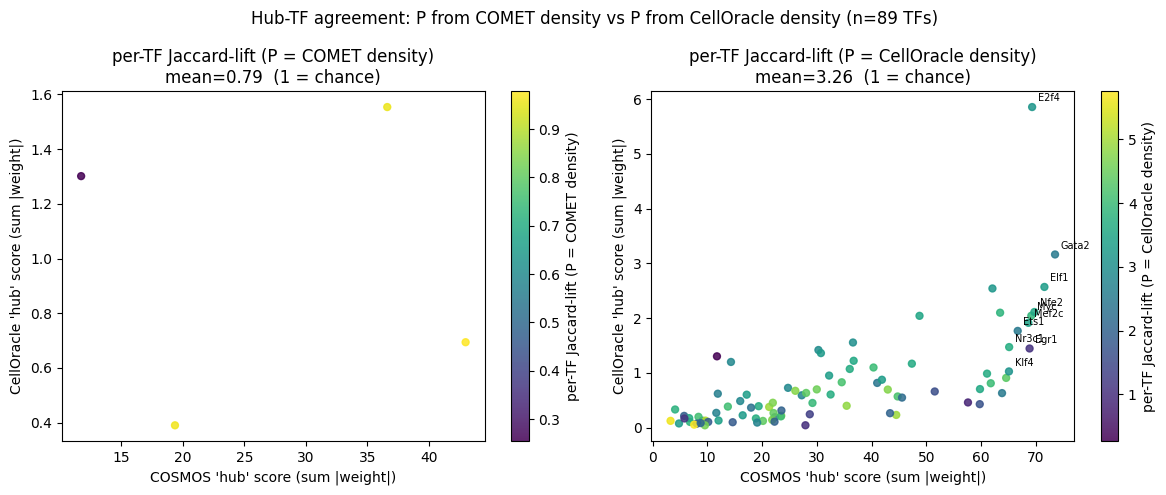

In [15]:
def per_tf_jaccard_lift_by(pred, ref, P_from="ref", eps=EPS, min_pos=10):
    """Density-matched per-TF Jaccard-lift, generalized to whichever side sets P.
    P_from='ref'  : P = CellOracle's nonzero count per TF (== per_tf_jaccard_lift above); take
                    COMET's top-P edges, compare to CellOracle's full edge set.
    P_from='pred' : P = COMET's nonzero count per TF; take CellOracle's top-P edges (capped at
                    CellOracle's own count -- usually all of it), compare to COMET's full edge set.
    Both sides are capped at their own available count, and chance is computed for the realized
    (possibly capped) sizes rather than assuming both hit P -- reduces exactly to the P_from='ref'
    cell above whenever no capping is needed."""
    T_ = pred.shape[1]; out = np.full(T_, np.nan)
    for t in range(T_):
        p, r = np.abs(pred[:, t]), np.abs(ref[:, t])
        p_nz, r_nz = np.flatnonzero(p > eps), np.flatnonzero(r > eps)
        cand = np.union1d(p_nz, r_nz); N = len(cand)
        fixed, other, other_nz = (r_nz, p, p_nz) if P_from == "ref" else (p_nz, r, r_nz)
        P = len(fixed)
        if P < min_pos or P >= N:
            continue
        other_top = np.argsort(other)[::-1][:min(P, len(other_nz))]
        ka, kb = P, len(other_top)
        inter = len(set(fixed.tolist()) & set(other_top.tolist()))
        obs = inter / (ka + kb - inter)
        exp = (ka * kb / N) / (ka + kb - ka * kb / N)   # chance Jaccard of size-ka, size-kb sets
        out[t] = obs / exp
    return out

tf_jacc_lift_cometP = per_tf_jaccard_lift_by(A_learned, co_global, P_from="pred")
n_scored_cometP = int(np.isfinite(tf_jacc_lift_cometP).sum())
print(f"COMET-density-P Jaccard-lift scored on {n_scored_cometP}/{T} TFs "
      f"(vs {n_scored}/{T} for the CellOracle-density-P version above)")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, shading, label in [(axes[0], tf_jacc_lift_cometP, "per-TF Jaccard-lift (P = COMET density)"),
                           (axes[1], tf_jacc_lift,        "per-TF Jaccard-lift (P = CellOracle density)")]:
    cmap = plt.cm.viridis.copy(); cmap.set_bad("lightgrey")
    sc = ax.scatter(hub_comet, hub_co, c=shading, cmap=cmap,
                    vmin=np.nanmin(shading), vmax=np.nanmax(shading), s=25, alpha=0.85)
    for ti in np.argsort(hub_comet + hub_co)[-10:]:
        ax.annotate(A_tfs[ti], (hub_comet[ti], hub_co[ti]), fontsize=7,
                    xytext=(4, 4), textcoords="offset points")
    ax.set_xlabel("COSMOS 'hub' score (sum |weight|)")
    ax.set_ylabel("CellOracle 'hub' score (sum |weight|)")
    ax.set_title(f"{label}\nmean={np.nanmean(shading):.2f}  (1 = chance)")
    fig.colorbar(sc, ax=ax, label=label)
fig.suptitle(f"Hub-TF agreement: P from COMET density vs P from CellOracle density (n={T} TFs)")
plt.tight_layout(); plt.show()

## Cell -> cluster matching using top-P Jaccard (P fixed by density, not a top-frac of the union)

Same task as the cluster-matching section above, but instead of taking the top `top_frac` of the
*union* on both sides (cell 14), `P` is now a per-TF edge count set by one side's own density and
capped on the other side -- same idea as the Jaccard-lift metric, minus the chance-normalization
(this is a discrimination task, so raw overlap magnitude is fine -- z-normalizing the score column
already removes per-cluster scale). Tries `P` from the CellOracle cluster's density (sparse, ~8%)
and from the cell's COMET density (dense, ~44%), and reports whichever gives the better matching
accuracy.

In [16]:
def topP_jaccard(ox, oy, P):
    """Jaccard between the top-P (by |weight|, pre-sorted) entries of two edge-index arrays,
    each capped at its own available count."""
    kx, ky = min(P, ox.size), min(P, oy.size)
    inter = np.intersect1d(ox[:kx], oy[:ky], assume_unique=True).size
    denom = kx + ky - inter
    return inter / denom if denom else np.nan


def mean_topP_jaccard_to_cluster(cell_orders, cl, P_from):
    """Mean over TFs of the top-P Jaccard between a cell's and a cluster's strongest edges.
    P_from='cluster' -> P = the CellOracle cluster's own per-TF edge count (sparse).
    P_from='cell'    -> P = the cell's own COMET-derived per-TF edge count (dense)."""
    j = []
    for t in range(T):
        ox, oy = cell_orders[t], cl_orders[cl][t]
        if ox.size == 0 or oy.size == 0:
            continue
        P = oy.size if P_from == "cluster" else ox.size
        j.append(topP_jaccard(ox, oy, P))
    return np.nanmean(j) if j else np.nan


scores_by_Pfrom = {"cluster": [], "cell": []}
for i in sample_idx:
    cell_abs = np.abs(A_base + np.einsum("d,dgt->gt", mix_weights[i], A_dict))
    cell_orders, _ = tf_orders(cell_abs)
    for P_from in scores_by_Pfrom:
        scores_by_Pfrom[P_from].append(
            [mean_topP_jaccard_to_cluster(cell_orders, cl, P_from) for cl in cluster_names])

topP_results = {}
own = np.array([cluster_names.index(a) for a in assigned])
for P_from, s in scores_by_Pfrom.items():
    s = np.array(s)
    Z_ = (s - np.nanmean(s, 0)) / np.nanstd(s, 0)
    Zf_ = np.where(np.isnan(Z_), -np.inf, Z_)
    pred_ = np.array(cluster_names)[Zf_.argmax(1)]
    ranks_ = (Z_ > Z_[np.arange(len(Z_)), own][:, None]).sum(1) + 1
    topP_results[P_from] = dict(scores=s, Z=Z_, predicted=pred_,
                                acc=(pred_ == assigned).mean(), ranks=ranks_)
    r = topP_results[P_from]
    print(f"P from {P_from:8s} (top-P Jaccard): acc={r['acc']:.3f}  "
          f"mean_rank={r['ranks'].mean():.2f}/{len(cluster_names)}  top3={(r['ranks']<=3).mean():.3f}")

best_P_from = max(topP_results, key=lambda k: topP_results[k]["acc"])
best = topP_results[best_P_from]
predicted_topP, ranks_topP, acc_topP = best["predicted"], best["ranks"], best["acc"]
print(f"\nBest: P from '{best_P_from}' -> acc={acc_topP:.3f}  "
      f"(top-{int(TOP_FRAC*100)}% union-Jaccard baseline: acc={acc:.3f}, shuffle={shuffle_acc.mean():.3f})")

P from cluster  (top-P Jaccard): acc=0.040  mean_rank=5.85/16  top3=0.235
P from cell     (top-P Jaccard): acc=0.058  mean_rank=8.44/16  top3=0.182

Best: P from 'cell' -> acc=0.058  (top-20% union-Jaccard baseline: acc=0.237, shuffle=0.062)


## Distribution of COMET's learned weights

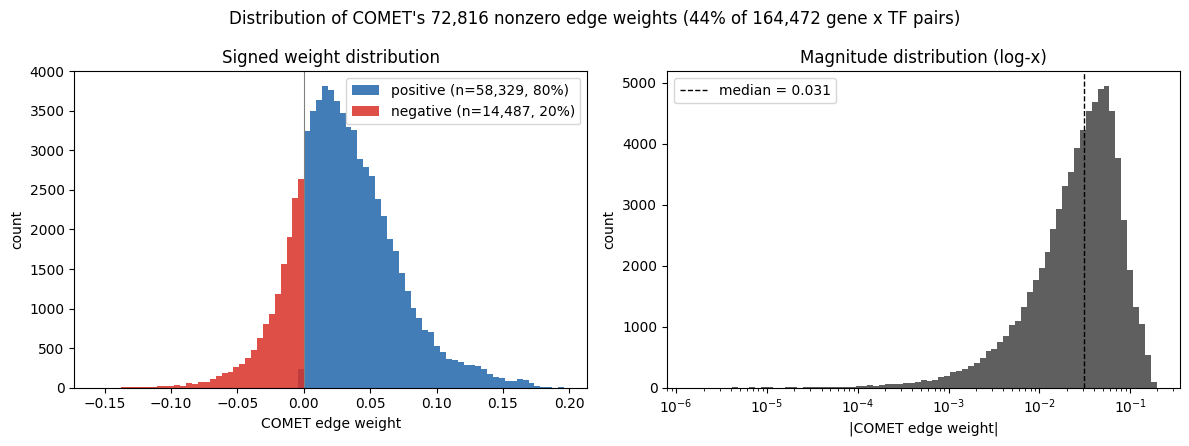

Nonzero edges: 72,816 / 164,472 (44.3%)
Sign split: 80.1% positive, 19.9% negative
|weight|: median=0.0310  mean=0.0386  max=0.1960


In [17]:
w_nz  = A_learned[np.abs(A_learned) > EPS]
w_pos = w_nz[w_nz > 0]
w_neg = w_nz[w_nz < 0]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

bins = np.linspace(w_nz.min(), w_nz.max(), 80)
ax1.hist(w_pos, bins=bins, color="#2166ac", alpha=0.85,
         label=f"positive (n={len(w_pos):,}, {len(w_pos) / len(w_nz):.0%})")
ax1.hist(w_neg, bins=bins, color="#d73027", alpha=0.85,
         label=f"negative (n={len(w_neg):,}, {len(w_neg) / len(w_nz):.0%})")
ax1.axvline(0, color="grey", lw=0.8)
ax1.set_xlabel("COMET edge weight"); ax1.set_ylabel("count")
ax1.set_title("Signed weight distribution")
ax1.legend()

log_bins = np.logspace(np.log10(np.abs(w_nz).min()), np.log10(np.abs(w_nz).max()), 80)
ax2.hist(np.abs(w_nz), bins=log_bins, color="#4d4d4d", alpha=0.9)
ax2.axvline(np.median(np.abs(w_nz)), color="black", ls="--", lw=1,
            label=f"median = {np.median(np.abs(w_nz)):.3f}")
ax2.set_xscale("log")
ax2.set_xlabel("|COMET edge weight|"); ax2.set_ylabel("count")
ax2.set_title("Magnitude distribution (log-x)")
ax2.legend()

fig.suptitle(f"Distribution of COMET's {len(w_nz):,} nonzero edge weights "
             f"({len(w_nz) / A_learned.size:.0%} of {A_learned.size:,} gene x TF pairs)")
plt.tight_layout(); plt.show()

print(f"Nonzero edges: {len(w_nz):,} / {A_learned.size:,} ({len(w_nz) / A_learned.size:.1%})")
print(f"Sign split: {len(w_pos) / len(w_nz):.1%} positive, {len(w_neg) / len(w_nz):.1%} negative")
print(f"|weight|: median={np.median(np.abs(w_nz)):.4f}  mean={np.mean(np.abs(w_nz)):.4f}  "
      f"max={np.abs(w_nz).max():.4f}")